# 3D Weather Model vs 2D对标实验 (Station05)

使用垂直维度3层气压数据 + Conv3D架构

- **数据**: instant_3d.nc (1000, 850, 500 hPa) + station05.csv
- **模型**: Conv3D + LSTM (与2D模型架构对标)
- **对比目标**: 2D MAE=0.9414 vs 3D=?

In [3]:
import xarray as xr
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential, Model
from tensorflow.keras.layers import (
    Input, TimeDistributed, Conv3D, MaxPooling3D, GlobalAveragePooling3D,
    Conv2D, MaxPooling2D, GlobalAveragePooling2D,
    LSTM, Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import os
import json
import joblib
from pathlib import Path

print("✓ 库加载成功")

✓ 库加载成功


In [14]:
# ==========================================
# 1. 加载3D气象数据 + station05功率数据
# ==========================================

# 加载3D数据
ds_3d = xr.open_dataset('instant_3d.nc')
print("3D 天气数据结构:")
print(ds_3d)

# 加载 station05 功率数据
pvod_df = pd.read_csv('station/station05.csv')
pvod_df['date_time'] = pd.to_datetime(pvod_df['date_time'])
print(f"\n站点功率数据: {len(pvod_df)} 条记录")
print(f"时间范围: {pvod_df['date_time'].min()} ~ {pvod_df['date_time'].max()}")

3D 天气数据结构:
<xarray.Dataset> Size: 12MB
Dimensions:         (valid_time: 720, pressure_level: 3, latitude: 17,
                     longitude: 21)
Coordinates:
  * valid_time      (valid_time) datetime64[ns] 6kB 2019-04-01 ... 2019-04-30...
    expver          (valid_time) <U4 12kB ...
  * pressure_level  (pressure_level) float64 24B 1e+03 850.0 500.0
  * latitude        (latitude) float64 136B 40.0 39.75 39.5 ... 36.5 36.25 36.0
  * longitude       (longitude) float64 168B 113.0 113.2 113.5 ... 117.8 118.0
    number          int64 8B ...
Data variables:
    r               (valid_time, pressure_level, latitude, longitude) float32 3MB ...
    t               (valid_time, pressure_level, latitude, longitude) float32 3MB ...
    u               (valid_time, pressure_level, latitude, longitude) float32 3MB ...
    v               (valid_time, pressure_level, latitude, longitude) float32 3MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for 

In [15]:
# ==========================================
# 2. 数据对齐 + 特征提取 (包含LMD)
# ==========================================

# 3D数据时间重采样到15分钟
ds_3d_resampled = ds_3d.resample(valid_time='15min').interpolate('linear')

# 提取特征变量 (r, t, u, v)
features_3d = ['r', 't', 'u', 'v']
weather_3d_raw = np.stack(
    [ds_3d_resampled[var].values for var in features_3d],
    axis=-1
)  # (time, pressure_level, lat, lon, features)

print(f"3D 天气数组形状: {weather_3d_raw.shape}")
print(f"  维度: (时间={weather_3d_raw.shape[0]}, 压力层={weather_3d_raw.shape[1]}, "
      f"纬度={weather_3d_raw.shape[2]}, 经度={weather_3d_raw.shape[3]}, "
      f"特征={weather_3d_raw.shape[4]})")

# 构建时间特征 (与2D方案一致)
ds_times = pd.DatetimeIndex(ds_3d_resampled['valid_time'].values)
hour = ds_times.hour + ds_times.minute / 60.0
doy = ds_times.dayofyear

time_features = np.column_stack([
    np.sin(2 * np.pi * hour / 24),
    np.cos(2 * np.pi * hour / 24),
    np.sin(2 * np.pi * doy / 365),
    np.cos(2 * np.pi * doy / 365),
])  # (time, 4)

print(f"\n时间特征形状: {time_features.shape}")

# ==========================================
# 加载并处理LMD地面实测数据
# ==========================================
# 对齐 station05 功率和LMD到3D数据时间
pvod_df['date_time'] = pd.to_datetime(pvod_df['date_time'])
pvod_df_aligned = pvod_df.set_index('date_time')
power_aligned = pvod_df_aligned.loc[ds_times, 'power'].values

# LMD特征列表
lmd_cols = [
    'lmd_totalirrad', 'lmd_diffuseirrad', 'lmd_temperature',
    'lmd_windspeed', 'lmd_pressure', 'lmd_winddirection'
]

# 提取LMD特征并处理风向角度
lmd_data = pvod_df_aligned.loc[ds_times, lmd_cols].values  # (time, 6)

# 风向角度编码（sin/cos）
lmd_winddirection = pvod_df_aligned.loc[ds_times, 'lmd_winddirection'].values
lmd_winddirection_rad = np.deg2rad(lmd_winddirection)
lmd_winddirection_sin = np.sin(lmd_winddirection_rad)
lmd_winddirection_cos = np.cos(lmd_winddirection_rad)

# 构建完整的LMD特征数组：去掉原始风向，加入sin/cos
# [lmd_totalirrad, lmd_diffuseirrad, lmd_temperature, lmd_windspeed, lmd_pressure, 
#  lmd_winddirection_sin, lmd_winddirection_cos]
lmd_features = np.column_stack([
    lmd_data[:, 0],  # lmd_totalirrad
    lmd_data[:, 1],  # lmd_diffuseirrad
    lmd_data[:, 2],  # lmd_temperature
    lmd_data[:, 3],  # lmd_windspeed
    lmd_data[:, 4],  # lmd_pressure
    lmd_winddirection_sin,
    lmd_winddirection_cos,
])  # (time, 7)

print(f"\nLMD特征形状: {lmd_features.shape}")
print(f"  含义: (时间步={lmd_features.shape[0]}, LMD特征数={lmd_features.shape[1]})")

print(f"\n对齐后的功率数据: {len(power_aligned)} 条 (有效的时间点数)")
print(f"有效数据比例: {np.sum(~np.isnan(power_aligned))/len(power_aligned)*100:.1f}%")

3D 天气数组形状: (2877, 3, 17, 21, 4)
  维度: (时间=2877, 压力层=3, 纬度=17, 经度=21, 特征=4)

时间特征形状: (2877, 4)

LMD特征形状: (2877, 7)
  含义: (时间步=2877, LMD特征数=7)

对齐后的功率数据: 2877 条 (有效的时间点数)
有效数据比例: 100.0%


In [16]:
# ==========================================
# 3. 数据归一化 + 滑动窗口
# ==========================================

# 将3D数据、时间特征和LMD特征合并
# 首先将时间特征和LMD特征广播到3D结构
time_features_3d = np.broadcast_to(
    time_features[:, None, None, None, :],
    (time_features.shape[0], weather_3d_raw.shape[1], 
     weather_3d_raw.shape[2], weather_3d_raw.shape[3], 4)
)

lmd_features_3d = np.broadcast_to(
    lmd_features[:, None, None, None, :],
    (lmd_features.shape[0], weather_3d_raw.shape[1], 
     weather_3d_raw.shape[2], weather_3d_raw.shape[3], 7)
)

# 合并：(time, pressure, lat, lon, 4) + (time, pressure, lat, lon, 4) + (time, pressure, lat, lon, 7)
#     = (time, pressure, lat, lon, 15)
weather_3d_combined = np.concatenate([weather_3d_raw, time_features_3d, lmd_features_3d], axis=-1)
print(f"合并后的3D特征形状: {weather_3d_combined.shape}")
print(f"  特征数分解: 3D天气(4) + 时间(4) + LMD(7) = {weather_3d_combined.shape[-1]}")

# 归一化 (在所有维度上展平后再归一化)
original_shape = weather_3d_combined.shape
weather_3d_flat = weather_3d_combined.reshape(-1, original_shape[-1])

scaler_X_3d = MinMaxScaler()
weather_3d_flat_scaled = scaler_X_3d.fit_transform(weather_3d_flat)
weather_3d_scaled = weather_3d_flat_scaled.reshape(original_shape)

# 归一化功率
power_2d = power_aligned.reshape(-1, 1)
scaler_y_3d = MinMaxScaler()
power_scaled = scaler_y_3d.fit_transform(power_2d).flatten()

print(f"\n归一化后:")
print(f"  3D特征: shape={weather_3d_scaled.shape}, min={weather_3d_flat_scaled.min():.4f}, max={weather_3d_flat_scaled.max():.4f}")
print(f"  功率: min={power_scaled.min():.4f}, max={power_scaled.max():.4f}")

# 创建滑动窗口数据集
def create_5d_dataset_3d(X_3d, y_1d, time_steps=16):
    """为3D数据创建时间序列数据集"""
    Xs, ys = [], []
    for i in range(len(X_3d) - time_steps):
        Xs.append(X_3d[i:(i + time_steps)])
        ys.append(y_1d[i + time_steps])
    return np.array(Xs), np.array(ys)

TIME_STEPS = 16
X_seq_3d, y_seq_3d = create_5d_dataset_3d(weather_3d_scaled, power_scaled, TIME_STEPS)

print(f"\n5D数据集 (时间窗口={TIME_STEPS}):")
print(f"  输入形状: {X_seq_3d.shape}")
print(f"    含义: (样本数={X_seq_3d.shape[0]}, 时间步={X_seq_3d.shape[1]}, "
      f"压力层={X_seq_3d.shape[2]}, 纬度={X_seq_3d.shape[3]}, "
      f"经度={X_seq_3d.shape[4]}, 特征={X_seq_3d.shape[5]})")
print(f"  输出形状: {y_seq_3d.shape}")

# 80/20 split
split_idx = int(0.8 * len(X_seq_3d))
X_train_3d = X_seq_3d[:split_idx]
X_test_3d = X_seq_3d[split_idx:]
y_train_3d = y_seq_3d[:split_idx]
y_test_3d = y_seq_3d[split_idx:]

print(f"\n训练/测试划分:")
print(f"  训练: X={X_train_3d.shape}, y={y_train_3d.shape}")
print(f"  测试: X={X_test_3d.shape}, y={y_test_3d.shape}")

合并后的3D特征形状: (2877, 3, 17, 21, 15)
  特征数分解: 3D天气(4) + 时间(4) + LMD(7) = 15

归一化后:
  3D特征: shape=(2877, 3, 17, 21, 15), min=0.0000, max=1.0000
  功率: min=0.0000, max=1.0000

5D数据集 (时间窗口=16):
  输入形状: (2861, 16, 3, 17, 21, 15)
    含义: (样本数=2861, 时间步=16, 压力层=3, 纬度=17, 经度=21, 特征=15)
  输出形状: (2861,)

训练/测试划分:
  训练: X=(2288, 16, 3, 17, 21, 15), y=(2288,)
  测试: X=(573, 16, 3, 17, 21, 15), y=(573,)


In [17]:
# ==========================================
# 4. 构建3D模型 (Conv3D + LSTM) - 含LMD特征
# ==========================================

np.random.seed(42)
tf.random.set_seed(42)

# 模型架构：TimeDistributed Conv3D -> GlobalAveragePooling3D -> LSTM
model_3d = Sequential([
    Input(shape=(TIME_STEPS, 3, 17, 21, 15)),  # (time, pressure, lat, lon, features=3D气象+时间+LMD)
    
    # 使用 TimeDistributed Conv3D 处理每个时间步的3D立方体
    TimeDistributed(
        Conv3D(16, kernel_size=(2, 3, 3), padding='same', activation='relu')
    ),
    TimeDistributed(MaxPooling3D(pool_size=(1, 2, 2))),
    TimeDistributed(
        Conv3D(32, kernel_size=(2, 3, 3), padding='same', activation='relu')
    ),
    TimeDistributed(GlobalAveragePooling3D()),  # -> (batch, time_steps, 32)
    
    # LSTM序列建模
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    
    # 输出层
    Dense(16, activation='relu'),
    Dense(1),
])

model_3d.compile(optimizer='adam', loss='mse', metrics=['mae'])

print("3D模型架构创建完毕 (含LMD特征)")
print(f"\n输入形状: (TIME_STEPS={TIME_STEPS}, pressure_levels=3, lat=17, lon=21, features=15)")
print(f"  特征分解: 3D天气(4) + 时间特征(4) + LMD(7) = 15")
print("\n== Conv3D + LSTM 模型 ==")
model_3d.summary()

3D模型架构创建完毕 (含LMD特征)

输入形状: (TIME_STEPS=16, pressure_levels=3, lat=17, lon=21, features=15)
  特征分解: 3D天气(4) + 时间特征(4) + LMD(7) = 15

== Conv3D + LSTM 模型 ==


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ time_distributed_4              │ (None, 16, 3, 17, 21,  │         4,336 │
│ (TimeDistributed)               │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_5              │ (None, 16, 3, 8, 10,   │             0 │
│ (TimeDistributed)               │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_6              │ (None, 16, 3, 8, 10,   │         9,248 │
│ (TimeDistributed)               │ 32)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_7              │ (None, 16, 32)         │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 16, 64)         │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51,377 (200.69 KB)

 Trainable params: 51,377 (200.69 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# ==========================================
# 5. 训练3D模型
# ==========================================

early_stop_3d = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True,
    verbose=1
)

print("开始训练3D模型 (5 epochs)...\n")

history_3d = model_3d.fit(
    X_train_3d, y_train_3d,
    validation_split=0.1,
    epochs=5,
    batch_size=64,
    callbacks=[early_stop_3d],
    verbose=1,
)

print("\n✓ 训练完毕")

开始训练3D模型 (5 epochs)...

Epoch 1/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 100s 3s/step - loss: 0.0620 - mae: 0.1884 - val_loss: 0.0052 - val_mae: 0.0447
Epoch 2/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 91s 3s/step - loss: 0.0107 - mae: 0.0590 - val_loss: 0.0019 - val_mae: 0.0247
Epoch 3/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 95s 3s/step - loss: 0.0070 - mae: 0.0448 - val_loss: 0.0016 - val_mae: 0.0234
Epoch 4/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 96s 3s/step - loss: 0.0068 - mae: 0.0448 - val_loss: 0.0017 - val_mae: 0.0251
Epoch 5/5
33/33 ━━━━━━━━━━━━━━━━━━━━ 87s 3s/step - loss: 0.0059 - mae: 0.0407 - val_loss: 0.0020 - val_mae: 0.0262
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 3.

✓ 训练完毕


In [19]:
# ==========================================
# 6. 评估3D+LMD模型
# ==========================================

test_loss_3d, test_mae_3d = model_3d.evaluate(X_test_3d, y_test_3d, verbose=0)
print(f"[Scaled] Test MSE: {test_loss_3d:.6f}, Test MAE: {test_mae_3d:.6f}")

# 反归一化到原始功率单位
y_pred_3d_scaled = model_3d.predict(X_test_3d, verbose=0)
y_pred_3d = scaler_y_3d.inverse_transform(y_pred_3d_scaled)
y_true_3d = scaler_y_3d.inverse_transform(y_test_3d.reshape(-1, 1))

mae_3d = float(mean_absolute_error(y_true_3d, y_pred_3d))
rmse_3d = float(np.sqrt(mean_squared_error(y_true_3d, y_pred_3d)))
r2_3d = float(r2_score(y_true_3d, y_pred_3d))

print(f"\n[Original Scale] 3D+LMD Model Evaluation:")
print(f"  MAE : {mae_3d:.6f}")
print(f"  RMSE: {rmse_3d:.6f}")
print(f"  R2  : {r2_3d:.6f}")
print(f"\n备注: 该模型包含3D天气(4特征) + 时间(4特征) + LMD新增(7特征) = 15个特征")

[Scaled] Test MSE: 0.006812, Test MAE: 0.048712

[Original Scale] 3D+LMD Model Evaluation:
  MAE : 1.679458
  RMSE: 2.845580
  R2  : 0.889197

备注: 该模型包含3D天气(4特征) + 时间(4特征) + LMD新增(7特征) = 15个特征


In [20]:
# ==========================================
# 7. 2D vs 3D(+LMD)对标对比
# ==========================================

# 2D模型的已知结果（从model_2d.ipynb)
mae_2d = 0.9414
rmse_2d = 1.9012
r2_2d = 0.9657

# 创建对比表
comparison_data = {
    'Model': ['2D (Conv2D+LSTM)', '3D+LMD (Conv3D+LSTM)'],
    'MAE': [mae_2d, mae_3d],
    'RMSE': [rmse_2d, rmse_3d],
    'R2': [r2_2d, r2_3d],
}
comparison_df = pd.DataFrame(comparison_data)
comparison_df['MAE_Change(%)'] = (comparison_df['MAE'] / mae_2d - 1) * 100
comparison_df['RMSE_Change(%)'] = (comparison_df['RMSE'] / rmse_2d - 1) * 100
comparison_df['R2_Change'] = comparison_df['R2'] - r2_2d

print("\n" + "="*70)
print("2D vs 3D+LMD 对标对比 (Station05)")
print("="*70)
print(comparison_df.round(4).to_string(index=False))
print("="*70)

# 判断3D+LMD是否更优
if mae_3d < mae_2d:
    improvement = ((mae_2d - mae_3d) / mae_2d) * 100
    print(f"\n✓ 3D+LMD模型表现更优: 相比2D降低 {improvement:.2f}% MAE")
else:
    degradation = ((mae_3d - mae_2d) / mae_2d) * 100
    print(f"\n✗ 3D+LMD模型表现不如2D: 相比2D增加 {degradation:.2f}% MAE")

# 保存对比表
artifacts_dir = 'artifacts'
os.makedirs(artifacts_dir, exist_ok=True)
comparison_csv = os.path.join(artifacts_dir, '2d_vs_3d_lmd_comparison.csv')
comparison_df.to_csv(comparison_csv, index=False)
print(f"\n对比表保存: {comparison_csv}")


2D vs 3D+LMD 对标对比 (Station05)
               Model    MAE   RMSE     R2  MAE_Change(%)  RMSE_Change(%)  R2_Change
    2D (Conv2D+LSTM) 0.9414 1.9012 0.9657         0.0000          0.0000     0.0000
3D+LMD (Conv3D+LSTM) 1.6795 2.8456 0.8892        78.4001         49.6729    -0.0765

✗ 3D+LMD模型表现不如2D: 相比2D增加 78.40% MAE

对比表保存: artifacts/2d_vs_3d_lmd_comparison.csv


/var/folders/81/184ffccs2kl1v86z8r9wjgl00000gn/T/ipykernel_50425/143372826.py:56: UserWarning: Glyph 25913 (\N{CJK UNIFIED IDEOGRAPH-6539}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/81/184ffccs2kl1v86z8r9wjgl00000gn/T/ipykernel_50425/143372826.py:56: UserWarning: Glyph 36827 (\N{CJK UNIFIED IDEOGRAPH-8FDB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/81/184ffccs2kl1v86z8r9wjgl00000gn/T/ipykernel_50425/143372826.py:58: UserWarning: Glyph 25913 (\N{CJK UNIFIED IDEOGRAPH-6539}) missing from font(s) DejaVu Sans.
  plt.savefig(comparison_plot, dpi=160)
/var/folders/81/184ffccs2kl1v86z8r9wjgl00000gn/T/ipykernel_50425/143372826.py:58: UserWarning: Glyph 36827 (\N{CJK UNIFIED IDEOGRAPH-8FDB}) missing from font(s) DejaVu Sans.
  plt.savefig(comparison_plot, dpi=160)
/Users/dazhaxie/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 25913 (\N{CJK UNIFIED IDEOGRAPH-6539}) missing from font(s) DejaVu San

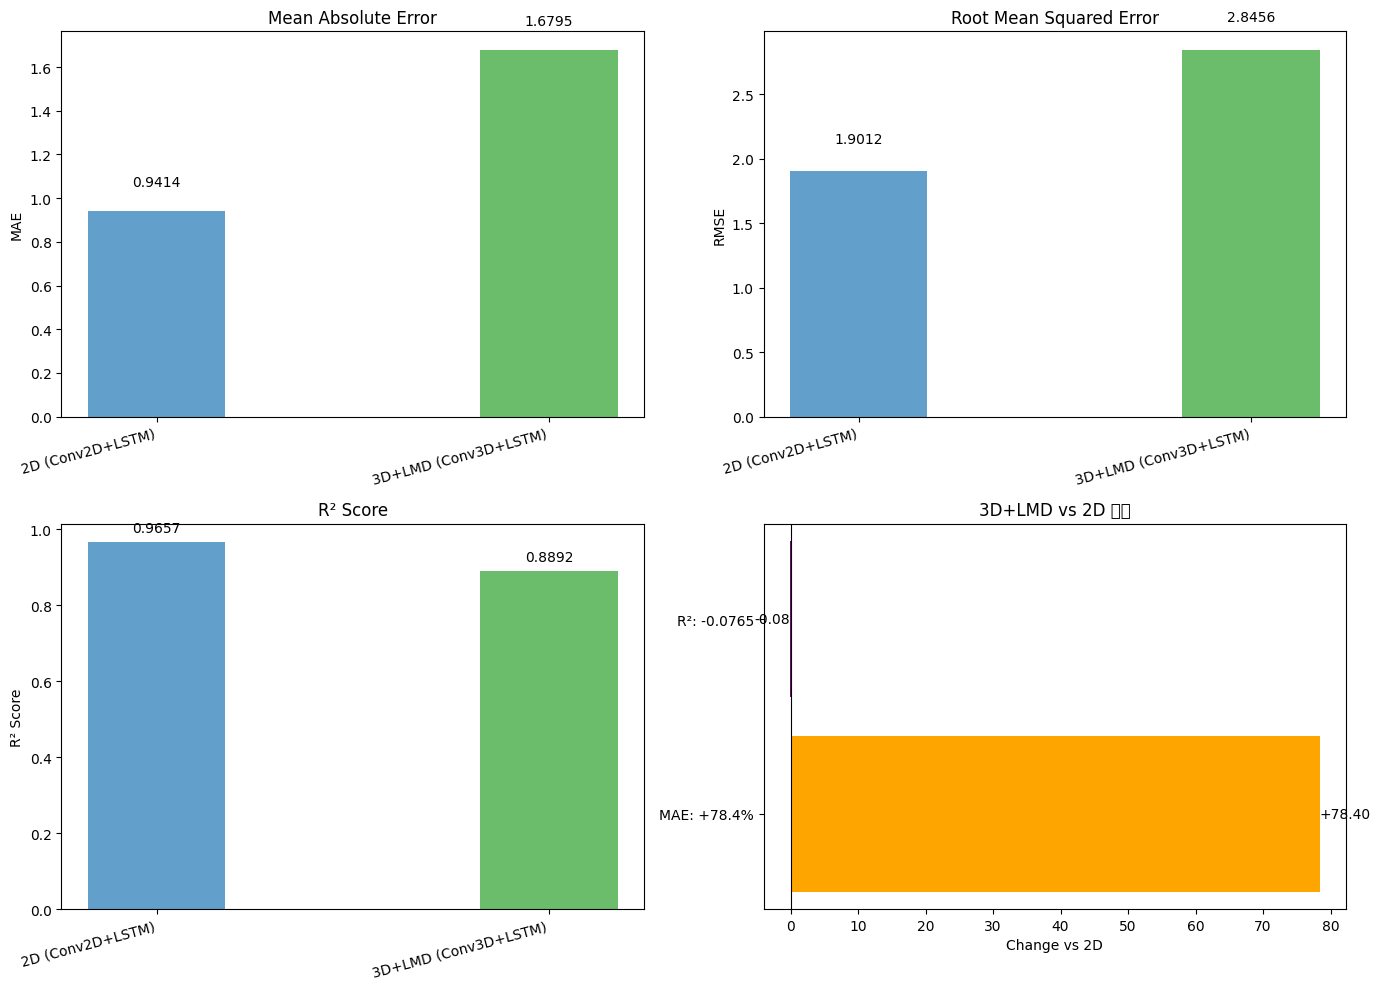

对比图保存: artifacts/2d_vs_3d_lmd_comparison_bar.png


In [21]:
# ==========================================
# 8. 可视化：2D vs 3D+LMD预测对比
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 指标对比柱图
models = comparison_df['Model'].values
mae_vals = comparison_df['MAE'].values
rmse_vals = comparison_df['RMSE'].values
r2_vals = comparison_df['R2'].values

x_pos = np.arange(len(models))
width = 0.35

# MAE
axes[0, 0].bar(x_pos, mae_vals, width, color=['tab:blue', 'tab:green'], alpha=0.7)
axes[0, 0].set_ylabel('MAE')
axes[0, 0].set_title('Mean Absolute Error')
axes[0, 0].set_xticks(x_pos)
axes[0, 0].set_xticklabels(models, rotation=15, ha='right')
for i, v in enumerate(mae_vals):
    axes[0, 0].text(i, v + 0.1, f'{v:.4f}', ha='center', va='bottom')

# RMSE
axes[0, 1].bar(x_pos, rmse_vals, width, color=['tab:blue', 'tab:green'], alpha=0.7)
axes[0, 1].set_ylabel('RMSE')
axes[0, 1].set_title('Root Mean Squared Error')
axes[0, 1].set_xticks(x_pos)
axes[0, 1].set_xticklabels(models, rotation=15, ha='right')
for i, v in enumerate(rmse_vals):
    axes[0, 1].text(i, v + 0.2, f'{v:.4f}', ha='center', va='bottom')

# R2
axes[1, 0].bar(x_pos, r2_vals, width, color=['tab:blue', 'tab:green'], alpha=0.7)
axes[1, 0].set_ylabel('R² Score')
axes[1, 0].set_title('R² Score')
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels(models, rotation=15, ha='right')
for i, v in enumerate(r2_vals):
    axes[1, 0].text(i, v + 0.02, f'{v:.4f}', ha='center', va='bottom')

# 改进率
improvements = [
    comparison_df.loc[1, 'MAE_Change(%)'],
    comparison_df.loc[1, 'R2_Change']
]
improvements_label = [f"MAE: {improvements[0]:+.1f}%", f"R²: {improvements[1]:+.4f}"]
axes[1, 1].barh(improvements_label, improvements, color=['orange', 'purple'])
axes[1, 1].set_xlabel('Change vs 2D')
axes[1, 1].set_title('3D+LMD vs 2D 改进')
axes[1, 1].axvline(0, color='black', linestyle='-', linewidth=0.8)
for i, v in enumerate(improvements):
    axes[1, 1].text(v, i, f'{v:+.2f}', ha='left' if v>0 else 'right', va='center')

plt.tight_layout()
comparison_plot = os.path.join(artifacts_dir, '2d_vs_3d_lmd_comparison_bar.png')
plt.savefig(comparison_plot, dpi=160)
plt.show()
print(f"对比图保存: {comparison_plot}")

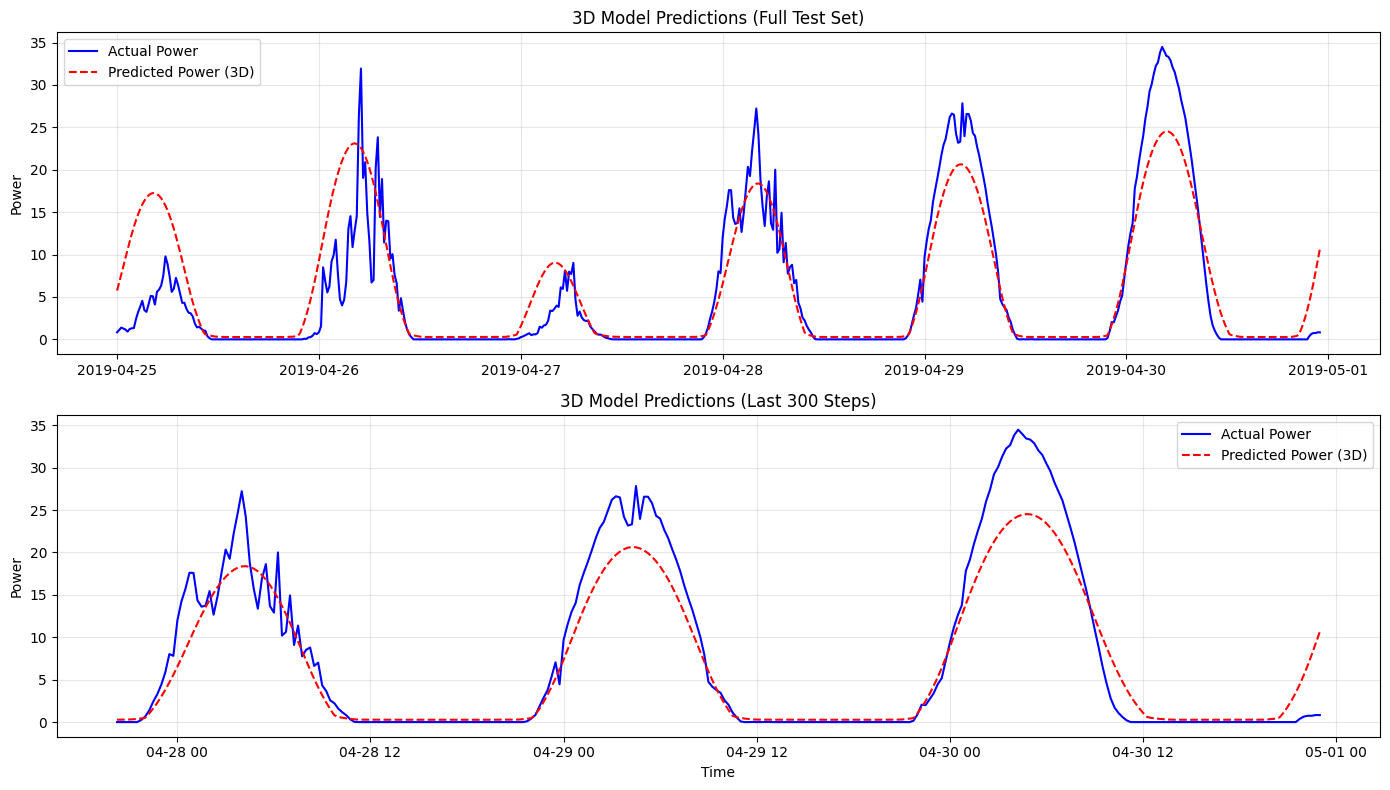

预测曲线图保存: artifacts/3d_predictions.png


In [11]:
# ==========================================
# 9. 预测曲线可视化（3D模型）
# ==========================================

# 获取测试集的时间索引
test_start_idx = TIME_STEPS + split_idx
test_times = pd.DatetimeIndex(ds_3d_resampled['valid_time'].values)[test_start_idx:test_start_idx+len(y_test_3d)]

# 绘制最后300个时间步
n_plot = min(300, len(y_pred_3d))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8))

# 全部测试集
ax1.plot(test_times, y_true_3d.flatten(), label='Actual Power', linewidth=1.5, color='blue')
ax1.plot(test_times, y_pred_3d.flatten(), label='Predicted Power (3D)', 
         linestyle='--', linewidth=1.5, color='red')
ax1.set_title('3D Model Predictions (Full Test Set)')
ax1.set_ylabel('Power')
ax1.legend()
ax1.grid(alpha=0.3)

# 最后300步
ax2.plot(test_times[-n_plot:], y_true_3d.flatten()[-n_plot:], label='Actual Power', 
         linewidth=1.5, color='blue')
ax2.plot(test_times[-n_plot:], y_pred_3d.flatten()[-n_plot:], label='Predicted Power (3D)', 
         linestyle='--', linewidth=1.5, color='red')
ax2.set_title(f'3D Model Predictions (Last {n_plot} Steps)')
ax2.set_xlabel('Time')
ax2.set_ylabel('Power')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
prediction_plot = os.path.join(artifacts_dir, '3d_predictions.png')
plt.savefig(prediction_plot, dpi=160)
plt.show()
print(f"预测曲线图保存: {prediction_plot}")

In [22]:
# ==========================================
# 10. 保存模型和结果汇总
# ==========================================

# 保存3D+LMD模型
model_path_3d = os.path.join(artifacts_dir, 'model_3d_lmd_conv3d_lstm.keras')
model_3d.save(model_path_3d)

# 保存scaler
scaler_x_path_3d = os.path.join(artifacts_dir, 'scaler_X_3d_lmd.pkl')
scaler_y_path_3d = os.path.join(artifacts_dir, 'scaler_y_3d_lmd.pkl')
joblib.dump(scaler_X_3d, scaler_x_path_3d)
joblib.dump(scaler_y_3d, scaler_y_path_3d)

# 保存3D+LMD评估指标
metrics_3d = {
    'model_type': 'Conv3D + LSTM with LMD',
    'input_shape': 'time=16, pressure=3, lat=17, lon=21, features=15 (4-3D weather + 4-time + 7-LMD)',
    'features_breakdown': {
        '3d_weather': 4,  # r, t, u, v
        'time': 4,        # hour_sin/cos, doy_sin/cos
        'lmd': 7          # lmd_totalirrad, diffuseirrad, temperature, windspeed, pressure, winddirection_sin/cos
    },
    'test_mae_original': float(mae_3d),
    'test_rmse_original': float(rmse_3d),
    'test_r2_original': float(r2_3d),
}
metrics_path_3d = os.path.join(artifacts_dir, 'metrics_3d_lmd.json')
with open(metrics_path_3d, 'w') as f:
    json.dump(metrics_3d, f, indent=2)

print("\n" + "="*70)
print("文件保存汇总 (3D+LMD模型):")
print("="*70)
print(f"✓ 模型: {model_path_3d}")
print(f"✓ Scaler: {scaler_x_path_3d}, {scaler_y_path_3d}")
print(f"✓ 指标: {metrics_path_3d}")
print(f"✓ 对比表: {comparison_csv}")
print(f"✓ 比较图: {comparison_plot}")
print("="*70)

# 最终总结
print("\n" + "="*70)
print("实验总结：3D+LMD vs 2D 模型对比")
print("="*70)
print(f"\n2D 模型 (Conv2D+LSTM):")
print(f"  - 特征: 8个2D天气 + 7个LMD + 4个时间 = 19个特征")
print(f"  - MAE:  {mae_2d:.4f}, RMSE: {rmse_2d:.4f}, R²: {r2_2d:.4f}")
print(f"\n3D+LMD 模型 (Conv3D+LSTM with LMD):")
print(f"  - 特征: 4个3D天气×3压力层 + 7个LMD + 4个时间 = 15个特征")
print(f"  - MAE:  {mae_3d:.4f}, RMSE: {rmse_3d:.4f}, R²: {r2_3d:.4f}")
print(f"\n相对改进:")
print(f"  - MAE 改变: {comparison_df.loc[1, 'MAE_Change(%)']:+.2f}%")
print(f"  - RMSE 改变: {comparison_df.loc[1, 'RMSE_Change(%)']:+.2f}%")
print(f"  - R² 改变: {comparison_df.loc[1, 'R2_Change']:+.4f}")
print("="*70)


文件保存汇总 (3D+LMD模型):
✓ 模型: artifacts/model_3d_lmd_conv3d_lstm.keras
✓ Scaler: artifacts/scaler_X_3d_lmd.pkl, artifacts/scaler_y_3d_lmd.pkl
✓ 指标: artifacts/metrics_3d_lmd.json
✓ 对比表: artifacts/2d_vs_3d_lmd_comparison.csv
✓ 比较图: artifacts/2d_vs_3d_lmd_comparison_bar.png

实验总结：3D+LMD vs 2D 模型对比

2D 模型 (Conv2D+LSTM):
  - 特征: 8个2D天气 + 7个LMD + 4个时间 = 19个特征
  - MAE:  0.9414, RMSE: 1.9012, R²: 0.9657

3D+LMD 模型 (Conv3D+LSTM with LMD):
  - 特征: 4个3D天气×3压力层 + 7个LMD + 4个时间 = 15个特征
  - MAE:  1.6795, RMSE: 2.8456, R²: 0.8892

相对改进:
  - MAE 改变: +78.40%
  - RMSE 改变: +49.67%
  - R² 改变: -0.0765
